In [2]:

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

from IPython.display import display

warnings.filterwarnings("default")
sns.set_theme(style="whitegrid")

SEED = 42
np.random.seed(SEED)

print("Libraries imported successfully.")


Libraries imported successfully.


In [3]:

DATA_FILE = Path("CC GENERAL.csv")

if not DATA_FILE.exists():
    raise FileNotFoundError(
        "CC GENERAL.csv was not found. "
        "Place the CSV file in the notebook folder."
    )

df = pd.read_csv(DATA_FILE)

required_columns = [
    "CUST_ID",
    "CREDIT_LIMIT",
    "PURCHASES",
    "BALANCE"
]

for column in required_columns:
    if column not in df.columns:
        raise ValueError(f"Missing column: {column}")

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


Shape after removing duplicates: (8950, 18)

Missing values:
CUST_ID                               0
BALANCE                               0
BALANCE_FREQUENCY                     0
PURCHASES                             0
ONEOFF_PURCHASES                      0
INSTALLMENTS_PURCHASES                0
CASH_ADVANCE                          0
PURCHASES_FREQUENCY                   0
ONEOFF_PURCHASES_FREQUENCY            0
PURCHASES_INSTALLMENTS_FREQUENCY      0
CASH_ADVANCE_FREQUENCY                0
CASH_ADVANCE_TRX                      0
PURCHASES_TRX                         0
CREDIT_LIMIT                          1
PAYMENTS                              0
MINIMUM_PAYMENTS                    313
PRC_FULL_PAYMENT                      0
TENURE                                0
dtype: int64

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1564.474828,2081.531879,0.000000,128.281915,873.385231,2054.140036,19043.13856
BALANCE_FREQUENCY,8950.0,0.877271,0.236904,0.000000,0.888889,1.000000,1.000000,1.00000
PURCHASES,8950.0,1003.204834,2136.634782,0.000000,39.635000,361.280000,1110.130000,49039.57000
ONEOFF_PURCHASES,8950.0,592.437371,1659.887917,0.000000,0.000000,38.000000,577.405000,40761.25000
INSTALLMENTS_PURCHASES,8950.0,411.067645,904.338115,0.000000,0.000000,89.000000,468.637500,22500.00000
CASH_ADVANCE,8950.0,978.871112,2097.163877,0.000000,0.000000,0.000000,1113.821139,47137.21176
PURCHASES_FREQUENCY,8950.0,0.490351,0.401371,0.000000,0.083333,0.500000,0.916667,1.00000
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.202458,0.298336,0.000000,0.000000,0.083333,0.300000,1.00000
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.364437,0.397448,0.000000,0.000000,0.166667,0.750000,1.00000
CASH_ADVANCE_FREQUENCY,8950.0,0.135144,0.200121,0.000000,0.000000,0.000000,0.222222,1.50000


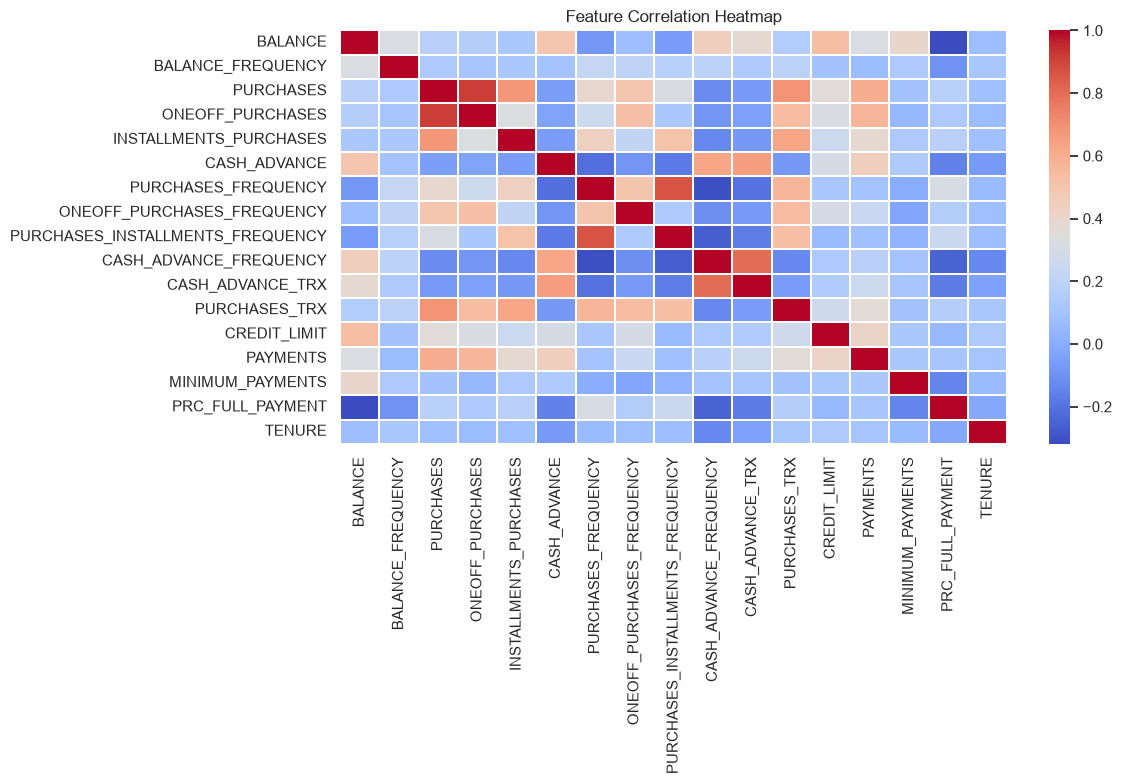

In [4]:

df = df.replace([np.inf, -np.inf], np.nan)
df = df.drop_duplicates().reset_index(drop=True)

customer_ids = df["CUST_ID"].copy()

print("Shape after removing duplicates:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

numeric_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

print("\nSummary statistics:")
display(df[numeric_columns].describe().T)

plt.figure(figsize=(12, 8))

corr = df.select_dtypes(include="number").corr()

sns.heatmap(
    corr,
    annot=False,
    cmap="coolwarm",
    linewidths=0.3
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

Credit limit threshold: 6000.0
Purchases threshold: 894.3159999999999

Class distribution:
HIGH_VALUE
0    7672
1    1278
Name: count, dtype: int64


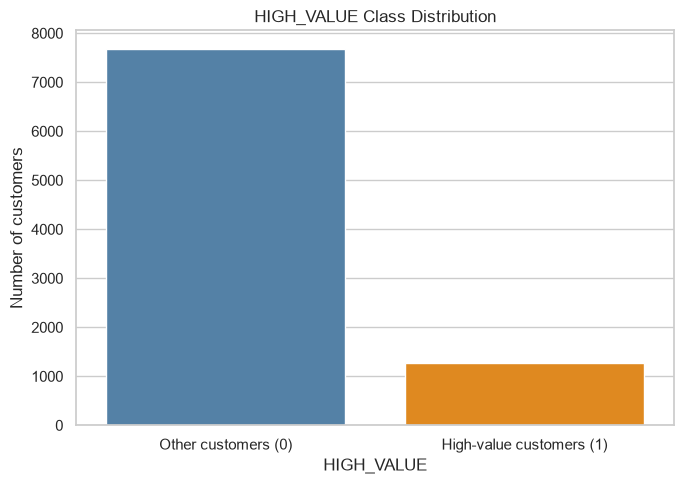

,Percentage
HIGH_VALUE,
Other,85.72067
High-value,14.27933


In [5]:

label_imputer = SimpleImputer(strategy="median")

df[["CREDIT_LIMIT", "PURCHASES"]] = (
    label_imputer.fit_transform(
        df[["CREDIT_LIMIT", "PURCHASES"]]
    )
)

credit_limit_threshold = df["CREDIT_LIMIT"].quantile(0.70)
purchases_threshold = df["PURCHASES"].quantile(0.70)

print("Credit limit threshold:", credit_limit_threshold)
print("Purchases threshold:", purchases_threshold)

df["HIGH_VALUE"] = (
    (df["CREDIT_LIMIT"] >= credit_limit_threshold)
    & (df["PURCHASES"] >= purchases_threshold)
).astype(int)

print("\nClass distribution:")
print(df["HIGH_VALUE"].value_counts().sort_index())

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="HIGH_VALUE",
    hue="HIGH_VALUE",
    order=[0, 1],
    palette={0: "steelblue", 1: "darkorange"},
    legend=False
)

plt.xticks(
    [0, 1],
    ["Other customers (0)", "High-value customers (1)"]
)

plt.title("HIGH_VALUE Class Distribution")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

display(
    (df["HIGH_VALUE"].value_counts(normalize=True) * 100)
    .sort_index()
    .rename(index={0: "Other", 1: "High-value"})
    .to_frame("Percentage")
)


In [6]:

kmeans_features = (
    df.select_dtypes(include=np.number)
    .drop(
        columns=[
            "HIGH_VALUE",
            "KMEANS_CLUSTER",
            "CUST_ID"
        ],
        errors="ignore"
    )
    .dropna(axis=1, how="all")
)

kmeans_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(
        n_clusters=2,
        random_state=SEED,
        n_init=10
    ))
])

df["KMEANS_CLUSTER"] = kmeans_pipeline.fit_predict(
    kmeans_features
)

print("Cluster distribution:")
print(df["KMEANS_CLUSTER"].value_counts().sort_index())

print("\nK-means vs percentile target:")
display(pd.crosstab(
    df["KMEANS_CLUSTER"],
    df["HIGH_VALUE"]
))


Cluster distribution:
KMEANS_CLUSTER
0    3707
1    5243
Name: count, dtype: int64

K-means vs percentile target:


HIGH_VALUE,0,1
KMEANS_CLUSTER,,
0,2617,1090
1,5055,188


In [7]:

visualization_features = [
    "CREDIT_LIMIT",
    "PURCHASES"
]

X_2d_raw = df[visualization_features].copy()
y_2d = df["HIGH_VALUE"].astype(int).copy()

imputer_2d = SimpleImputer(strategy="median")
scaler_2d = StandardScaler()

X_2d_imputed = imputer_2d.fit_transform(X_2d_raw)

X_2d_scaled = scaler_2d.fit_transform(
    X_2d_imputed
)

X_plot = X_2d_scaled
y_plot = y_2d.to_numpy()

print("Features:", visualization_features)
print("Customers:", len(X_plot))
print("Class distribution:")
print(pd.Series(y_plot).value_counts().sort_index())


Features: ['CREDIT_LIMIT', 'PURCHASES']
Customers: 8950
Class distribution:
0    7672
1    1278
Name: count, dtype: int64


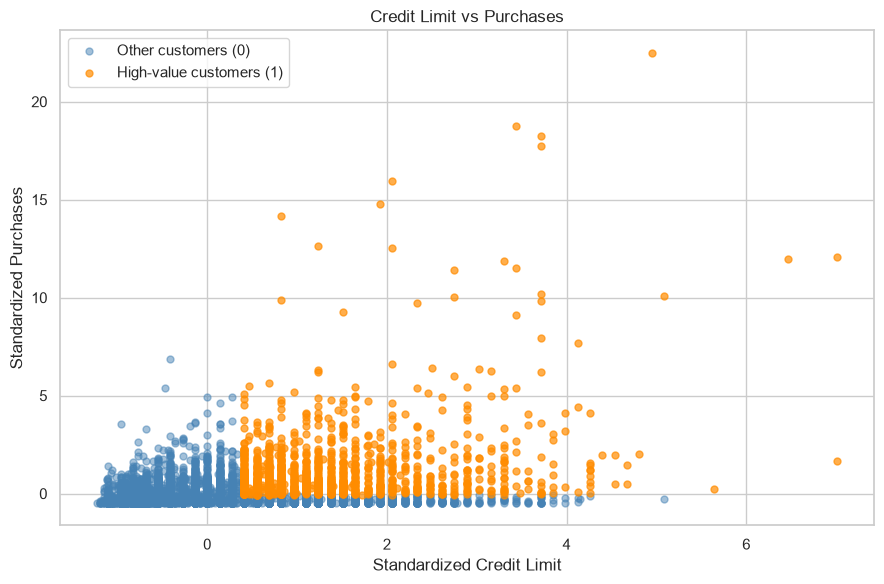

In [8]:

plt.figure(figsize=(9, 6))

plt.scatter(
    X_plot[y_plot == 0, 0],
    X_plot[y_plot == 0, 1],
    color="steelblue",
    alpha=0.5,
    s=25,
    label="Other customers (0)"
)

plt.scatter(
    X_plot[y_plot == 1, 0],
    X_plot[y_plot == 1, 1],
    color="darkorange",
    alpha=0.7,
    s=25,
    label="High-value customers (1)"
)

plt.title("Credit Limit vs Purchases")
plt.xlabel("Standardized Credit Limit")
plt.ylabel("Standardized Purchases")
plt.legend()
plt.tight_layout()
plt.show()


Original customers: 8950
Customers shown in filtered graph: 8765
Customers excluded from this graph: 185

Filtered class distribution:
0    7610
1    1155
Name: count, dtype: int64


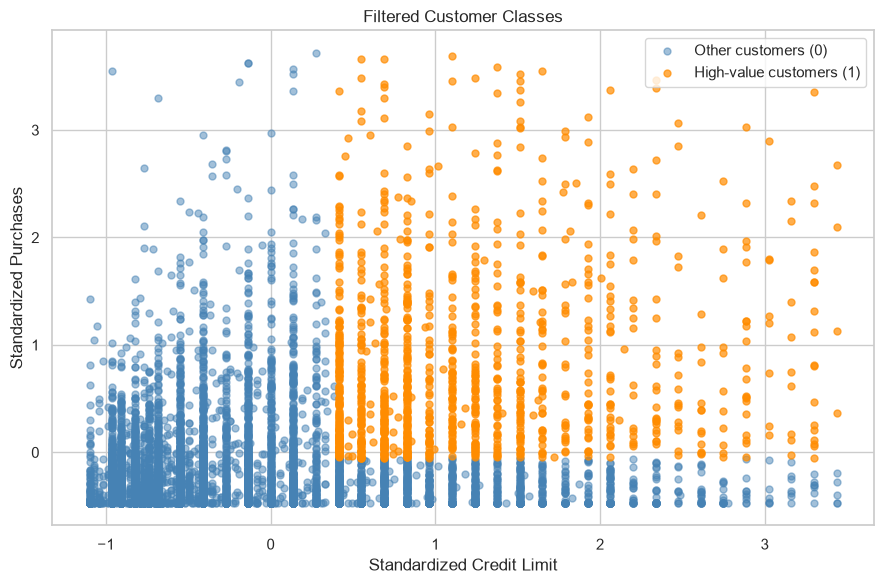

In [9]:

# Keep customers within the 1st to 99th percentile
# of each standardized feature for a clearer display.
lower_bounds = np.percentile(X_plot, 1, axis=0)
upper_bounds = np.percentile(X_plot, 99, axis=0)

visual_mask = (
    (X_plot[:, 0] >= lower_bounds[0])
    & (X_plot[:, 0] <= upper_bounds[0])
    & (X_plot[:, 1] >= lower_bounds[1])
    & (X_plot[:, 1] <= upper_bounds[1])
)

X_filtered = X_plot[visual_mask]
y_filtered = y_plot[visual_mask]

print("Original customers:", len(X_plot))
print("Customers shown in filtered graph:", len(X_filtered))
print("Customers excluded from this graph:", len(X_plot) - len(X_filtered))

print("\nFiltered class distribution:")
print(pd.Series(y_filtered).value_counts().sort_index())

plt.figure(figsize=(9, 6))

plt.scatter(
    X_filtered[y_filtered == 0, 0],
    X_filtered[y_filtered == 0, 1],
    color="steelblue",
    alpha=0.5,
    s=25,
    label="Other customers (0)"
)

plt.scatter(
    X_filtered[y_filtered == 1, 0],
    X_filtered[y_filtered == 1, 1],
    color="darkorange",
    alpha=0.7,
    s=25,
    label="High-value customers (1)"
)

plt.title("Filtered Customer Classes")
plt.xlabel("Standardized Credit Limit")
plt.ylabel("Standardized Purchases")
plt.legend()
plt.tight_layout()
plt.show()


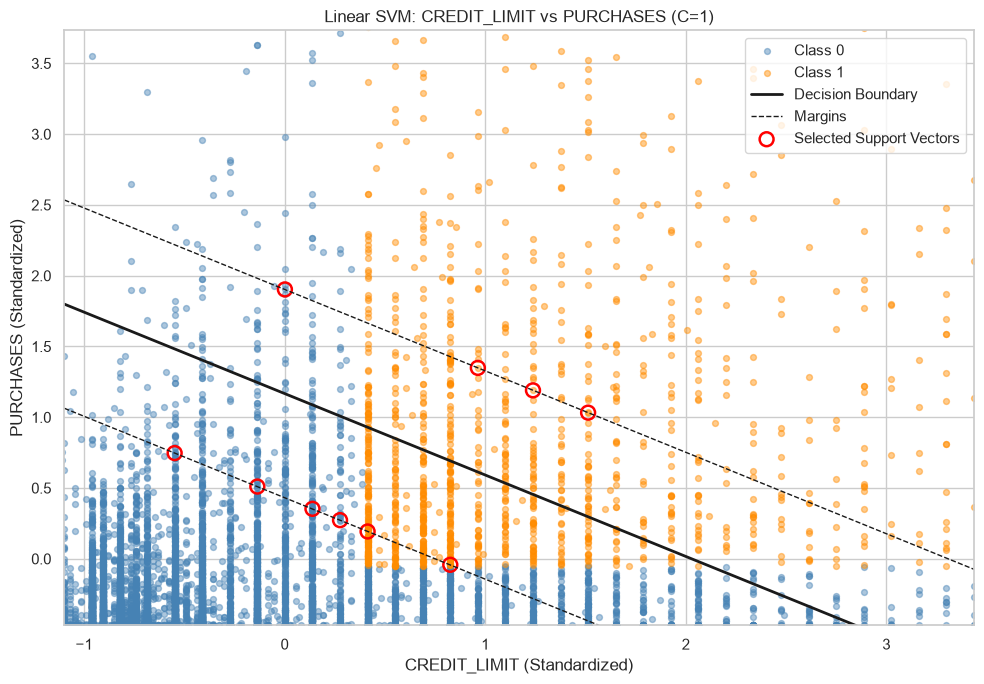

Total support vectors: 1662
Highlighted support vectors: 10
Margin width: 1.275451065291038


In [10]:
# Use all data; do not remove outliers or change labels

model = SVC(kernel="linear", C=1)
model.fit(X_2d_scaled, y_2d)

w = model.coef_[0]
b = model.intercept_[0]

x_min, x_max = np.percentile(X_2d_scaled[:, 0], [1, 99])
y_min, y_max = np.percentile(X_2d_scaled[:, 1], [1, 99])

xx = np.linspace(x_min, x_max, 300)

if abs(w[1]) > 1e-10:
    decision_boundary = -(w[0] * xx + b) / w[1]
    margin_positive = -(w[0] * xx + b - 1) / w[1]
    margin_negative = -(w[0] * xx + b + 1) / w[1]

    plt.figure(figsize=(10, 7))

    plt.scatter(
        X_2d_scaled[y_2d.to_numpy() == 0, 0],
        X_2d_scaled[y_2d.to_numpy() == 0, 1],
        color="steelblue", alpha=0.45, s=18, label="Class 0"
    )

    plt.scatter(
        X_2d_scaled[y_2d.to_numpy() == 1, 0],
        X_2d_scaled[y_2d.to_numpy() == 1, 1],
        color="darkorange", alpha=0.45, s=18, label="Class 1"
    )

    plt.plot(xx, decision_boundary, "k-", linewidth=2,
             label="Decision Boundary")
    plt.plot(xx, margin_positive, "k--", linewidth=1,
             label="Margins")
    plt.plot(xx, margin_negative, "k--", linewidth=1)

    # Highlight only 10 actual support vectors closest to the margins
    support_indices = model.support_
    support_scores = model.decision_function(X_2d_scaled[support_indices])

    closest = np.argsort(np.abs(np.abs(support_scores) - 1))[:10]
    selected_indices = support_indices[closest]

    plt.scatter(
        X_2d_scaled[selected_indices, 0],
        X_2d_scaled[selected_indices, 1],
        facecolors="none", edgecolors="red",
        s=100, linewidths=1.8, label="Selected Support Vectors"
    )

    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)
    plt.xlabel("CREDIT_LIMIT (Standardized)")
    plt.ylabel("PURCHASES (Standardized)")
    plt.title("Linear SVM: CREDIT_LIMIT vs PURCHASES (C=1)")
    plt.legend()
    plt.tight_layout()
    plt.show()

    print("Total support vectors:", len(model.support_))
    print("Highlighted support vectors:", len(selected_indices))
    print("Margin width:", 2 / np.linalg.norm(w))
else:
    print("Cannot plot boundary: coefficient for PURCHASES is near zero.")

C=0.1 | Total support vectors=1684 | Highlighted=10 | Margin width=1.3101
C=1 | Total support vectors=1662 | Highlighted=10 | Margin width=1.2755
C=10 | Total support vectors=1660 | Highlighted=10 | Margin width=1.2736
C=100 | Total support vectors=1660 | Highlighted=10 | Margin width=1.2733


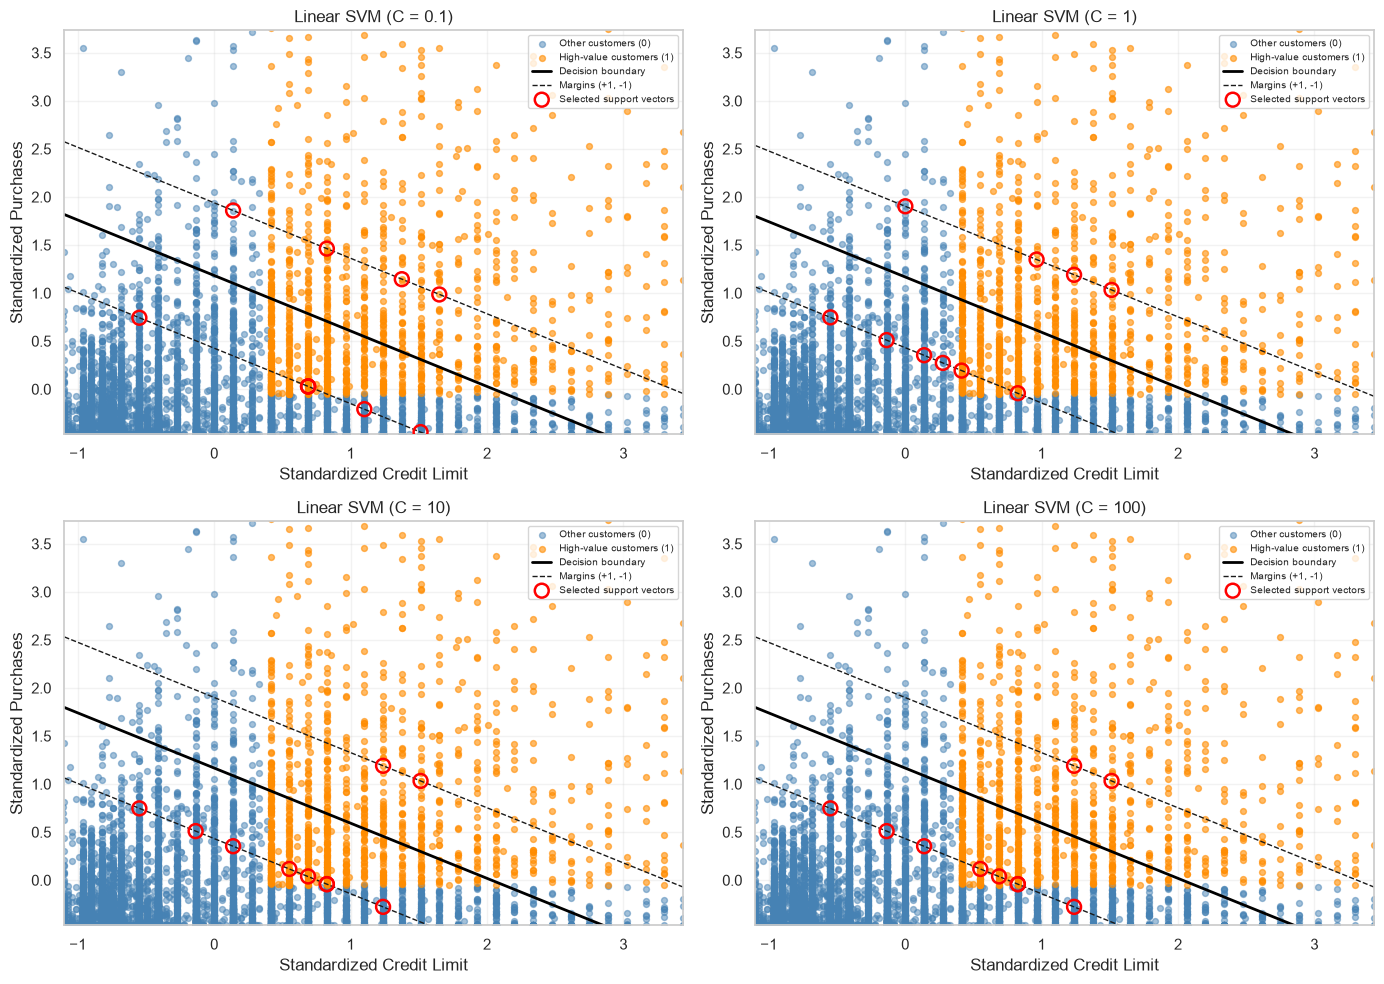

In [11]:

C_values = [0.1, 1, 10, 100]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

# Display limits only — training data is not removed
x_min = np.percentile(X_2d_scaled[:, 0], 1)
x_max = np.percentile(X_2d_scaled[:, 0], 99)
y_min = np.percentile(X_2d_scaled[:, 1], 1)
y_max = np.percentile(X_2d_scaled[:, 1], 99)

xx = np.linspace(x_min, x_max, 300)

for ax, c_value in zip(axes, C_values):

    svm = SVC(kernel="linear", C=c_value)
    svm.fit(X_2d_scaled, y_2d)

    w = svm.coef_[0]
    b = svm.intercept_[0]

    # Avoid division by zero when drawing the lines
    if abs(w[1]) < 1e-10:
        print(f"C={c_value}: cannot draw using this axis orientation.")
        continue

    # Decision boundary: decision score = 0
    boundary = -(w[0] * xx + b) / w[1]

    # Margin lines: decision score = +1 and -1
    margin_positive = -(w[0] * xx + b - 1) / w[1]
    margin_negative = -(w[0] * xx + b + 1) / w[1]

    # Original class colours
    ax.scatter(
        X_2d_scaled[y_2d.to_numpy() == 0, 0],
        X_2d_scaled[y_2d.to_numpy() == 0, 1],
        color="steelblue",
        s=18,
        alpha=0.5,
        label="Other customers (0)"
    )

    ax.scatter(
        X_2d_scaled[y_2d.to_numpy() == 1, 0],
        X_2d_scaled[y_2d.to_numpy() == 1, 1],
        color="darkorange",
        s=18,
        alpha=0.6,
        label="High-value customers (1)"
    )

    ax.plot(
        xx, boundary,
        color="black", linewidth=2,
        label="Decision boundary"
    )

    ax.plot(
        xx, margin_positive,
        "k--", linewidth=1,
        label="Margins (+1, -1)"
    )

    ax.plot(
        xx, margin_negative,
        "k--", linewidth=1
    )

    # Actual support vectors from this fitted model
    support_vectors = svm.support_vectors_
    support_scores = np.abs(
        svm.decision_function(support_vectors)
    )

    # Select actual support vectors closest to margin score ±1
    selected = np.argsort(
        np.abs(support_scores - 1)
    )[:10]

    selected_sv = support_vectors[selected]

    ax.scatter(
        selected_sv[:, 0],
        selected_sv[:, 1],
        s=100,
        facecolors="none",
        edgecolors="red",
        linewidths=1.8,
        label="Selected support vectors",
        zorder=5
    )

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_title(f"Linear SVM (C = {c_value})")
    ax.set_xlabel("Standardized Credit Limit")
    ax.set_ylabel("Standardized Purchases")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=7)

    margin_width = 2 / np.linalg.norm(w)

    print(
        f"C={c_value} | "
        f"Total support vectors={len(support_vectors)} | "
        f"Highlighted={len(selected_sv)} | "
        f"Margin width={margin_width:.4f}"
    )

plt.tight_layout()
plt.show()


In [12]:

excluded_columns = [
    "CUST_ID",
    "HIGH_VALUE",
    "KMEANS_CLUSTER",
    "CREDIT_LIMIT",
    "PURCHASES"
]

X = (
    df.select_dtypes(include=np.number)
    .drop(columns=excluded_columns, errors="ignore")
    .replace([np.inf, -np.inf], np.nan)
    .copy()
)

X = X.dropna(axis=1, how="all")
y = df["HIGH_VALUE"].astype(int)

customer_ids = df["CUST_ID"].copy()

if X.shape[1] == 0:
    raise ValueError("No usable numeric features remain.")

print("Feature count:", X.shape[1])
print("Features:", X.columns.tolist())
print("Target counts:")
print(y.value_counts())


Feature count: 15
Features: ['BALANCE', 'BALANCE_FREQUENCY', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']
Target counts:
HIGH_VALUE
0    7672
1    1278
Name: count, dtype: int64


In [13]:

all_indices = np.arange(len(df))

train_indices, temporary_indices = train_test_split(
    all_indices,
    test_size=0.40,
    random_state=SEED,
    stratify=y
)

validation_indices, test_indices = train_test_split(
    temporary_indices,
    test_size=0.50,
    random_state=SEED,
    stratify=y.iloc[temporary_indices]
)
     
X_train = X.iloc[train_indices]
y_train = y.iloc[train_indices]

X_validation = X.iloc[validation_indices]
y_validation = y.iloc[validation_indices]

X_test = X.iloc[test_indices]
y_test = y.iloc[test_indices]

print("Training rows:", len(X_train))
print("Validation rows:", len(X_validation))
print("Testing rows:", len(X_test))


Training rows: 5370
Validation rows: 1790
Testing rows: 1790


In [14]:

c_values_full = [0.01, 0.1, 1, 10, 100]
class_weights = [None, "balanced"]

best_c = None
best_class_weight = None
best_validation_f1 = -1

tuning_results = []

for c_value in c_values_full:
    for class_weight in class_weights:

        candidate = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("svm", SVC(
                kernel="linear",
                C=c_value,
                class_weight=class_weight
            ))
        ])

        candidate.fit(X_train, y_train)
        predictions = candidate.predict(X_validation)

        val_f1 = f1_score(
            y_validation,
            predictions,
            zero_division=0
        )

        tuning_results.append({
            "C": c_value,
            "Class Weight": (
                class_weight if class_weight else "None"
            ),
            "Validation F1": val_f1
        })

        if val_f1 > best_validation_f1:
            best_validation_f1 = val_f1
            best_c = c_value
            best_class_weight = class_weight

display(
    pd.DataFrame(tuning_results)
    .sort_values("Validation F1", ascending=False)
    .round(4)
)

print("Best C:", best_c)
print("Best class weight:", best_class_weight)
print("Best validation F1:", round(best_validation_f1, 4))


,C,Class Weight,Validation F1
7,10.00,balanced,0.6286
9,100.00,balanced,0.6286
3,0.10,balanced,0.6270
5,1.00,balanced,0.6266
1,0.01,balanced,0.6139
6,10.00,None,0.5694
8,100.00,None,0.5659
4,1.00,None,0.5659
2,0.10,None,0.5625
0,0.01,None,0.5473


Best C: 10
Best class weight: balanced
Best validation F1: 0.6286


Accuracy: 0.8642
Precision: 0.5144
Recall: 0.8392
F1-score: 0.6379


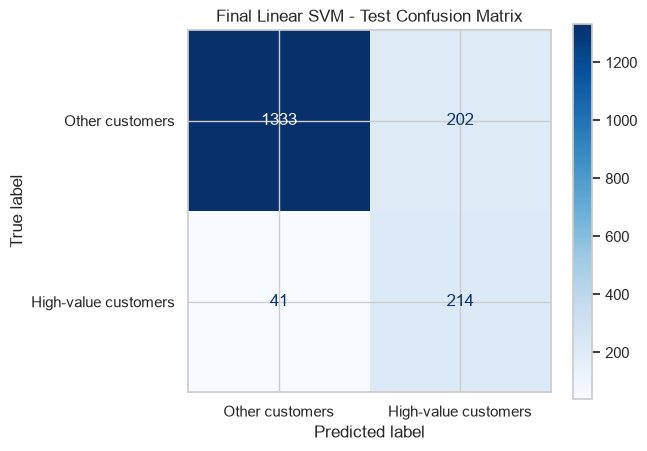

                      precision    recall  f1-score   support

     Other customers       0.97      0.87      0.92      1535
High-value customers       0.51      0.84      0.64       255

            accuracy                           0.86      1790
           macro avg       0.74      0.85      0.78      1790
        weighted avg       0.91      0.86      0.88      1790



In [15]:

train_validation_indices = np.concatenate([
    train_indices,
    validation_indices
])

X_train_validation = X.iloc[train_validation_indices]
y_train_validation = y.iloc[train_validation_indices]

svm_final_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="linear",
        C=best_c,
        class_weight=best_class_weight
    ))
])

svm_final_pipeline.fit(
    X_train_validation,
    y_train_validation
)

y_test_pred = svm_final_pipeline.predict(X_test)

svm_test_accuracy = accuracy_score(y_test, y_test_pred)
svm_test_precision = precision_score(
    y_test, y_test_pred, zero_division=0
)
svm_test_recall = recall_score(
    y_test, y_test_pred, zero_division=0
)
svm_test_f1 = f1_score(
    y_test, y_test_pred, zero_division=0
)

print("Accuracy:", round(svm_test_accuracy, 4))
print("Precision:", round(svm_test_precision, 4))
print("Recall:", round(svm_test_recall, 4))
print("F1-score:", round(svm_test_f1, 4))

cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Other customers", "High-value customers"]
).plot(cmap="Blues", values_format="d")

plt.title("Final Linear SVM - Test Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=["Other customers", "High-value customers"],
    zero_division=0
))


,Model,Accuracy,Precision,Recall,F1-score
0,Linear SVM,0.8642,0.5144,0.8392,0.6379
1,Logistic Regression,0.8631,0.5127,0.7922,0.6225


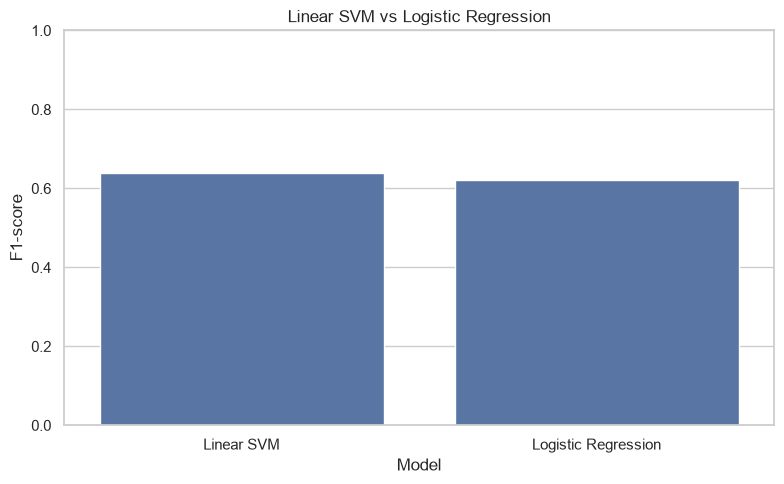

In [16]:

logistic_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        max_iter=3000,
        random_state=SEED,
        class_weight=best_class_weight
    ))
])

logistic_pipeline.fit(
    X_train_validation,
    y_train_validation
)

logistic_predictions = logistic_pipeline.predict(X_test)

logistic_test_f1 = f1_score(
    y_test,
    logistic_predictions,
    zero_division=0
)

model_comparison = pd.DataFrame([
    {
        "Model": "Linear SVM",
        "Accuracy": accuracy_score(y_test, y_test_pred),
        "Precision": precision_score(
            y_test, y_test_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_test_pred, zero_division=0
        ),
        "F1-score": svm_test_f1
    },
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(
            y_test, logistic_predictions
        ),
        "Precision": precision_score(
            y_test, logistic_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, logistic_predictions, zero_division=0
        ),
        "F1-score": logistic_test_f1
    }
])

display(model_comparison.round(4))

plt.figure(figsize=(8, 5))
sns.barplot(data=model_comparison, x="Model", y="F1-score")
plt.title("Linear SVM vs Logistic Regression")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


,Feature,Coefficient,Absolute Weight
0,ONEOFF_PURCHASES,1.7071,1.7071
1,INSTALLMENTS_PURCHASES,1.1310,1.1310
2,BALANCE,0.4569,0.4569
3,ONEOFF_PURCHASES_FREQUENCY,0.4513,0.4513
4,MINIMUM_PAYMENTS,-0.2686,0.2686
5,PURCHASES_INSTALLMENTS_FREQUENCY,0.2632,0.2632
6,PURCHASES_TRX,-0.1975,0.1975
7,TENURE,0.1922,0.1922
8,BALANCE_FREQUENCY,-0.0938,0.0938
9,CASH_ADVANCE,0.0871,0.0871


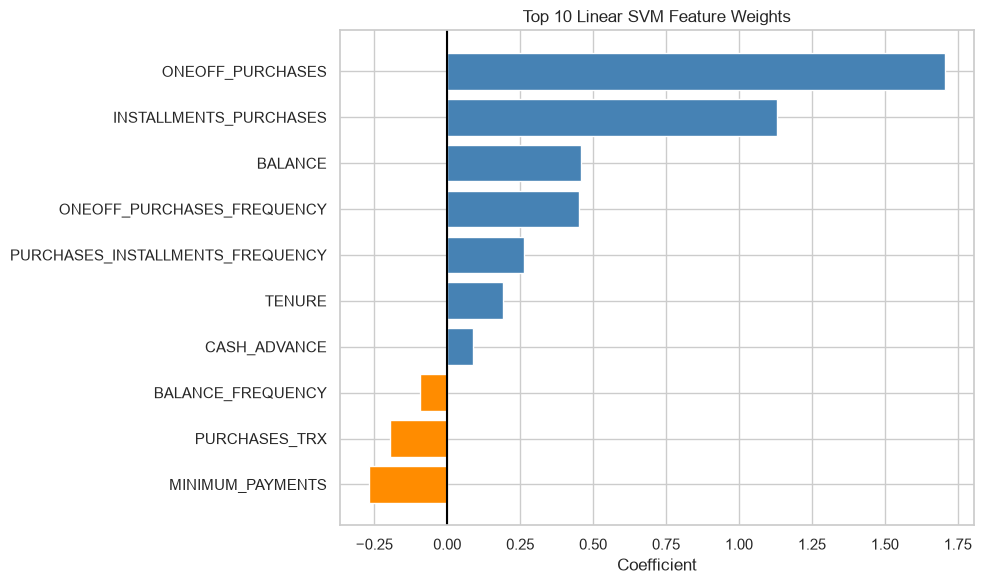

Positive coefficients push the decision score toward class 1.
Negative coefficients push the decision score toward class 0.


In [17]:

final_svm_model = svm_final_pipeline.named_steps["svm"]

feature_weights = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": final_svm_model.coef_[0]
})

feature_weights["Absolute Weight"] = (
    feature_weights["Coefficient"].abs()
)

feature_weights = feature_weights.sort_values(
    "Absolute Weight",
    ascending=False
).reset_index(drop=True)

top_10 = feature_weights.head(10)

display(top_10.round(4))

plot_data = top_10.sort_values("Coefficient")

colors = [
    "steelblue" if value >= 0 else "darkorange"
    for value in plot_data["Coefficient"]
]

plt.figure(figsize=(10, 6))
plt.barh(
    plot_data["Feature"],
    plot_data["Coefficient"],
    color=colors
)
plt.axvline(0, color="black")
plt.title("Top 10 Linear SVM Feature Weights")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()

print("Positive coefficients push the decision score toward class 1.")
print("Negative coefficients push the decision score toward class 0.")


In [18]:

support_vector_positions = final_svm_model.support_

support_vector_row_indices = train_validation_indices[
    support_vector_positions
]

borderline_customers = pd.DataFrame({
    "CUST_ID": customer_ids.iloc[
        support_vector_row_indices
    ].to_numpy(),
    "Actual HIGH_VALUE": y.iloc[
        support_vector_row_indices
    ].to_numpy(),
    "Predicted HIGH_VALUE": svm_final_pipeline.predict(
        X.iloc[support_vector_row_indices]
    )
})

print("Total support vectors:", len(borderline_customers))
display(borderline_customers.head(20))


Total support vectors: 2412


,CUST_ID,Actual HIGH_VALUE,Predicted HIGH_VALUE
0,C10372,0,0
1,C11840,0,0
2,C14978,0,0
3,C16844,0,1
4,C12314,0,0
5,C10419,0,0
6,C10186,0,1
7,C18179,0,0
8,C16317,0,1
9,C16433,0,1


In [19]:

print("BUSINESS RECOMMENDATIONS")
print("=" * 35)

for number, row in enumerate(
    top_10.head(3).itertuples(index=False),
    start=1
):
    feature = row.Feature
    coefficient = row.Coefficient

    if coefficient > 0:
        print(
            f"{number}. Monitor {feature}: higher standardized values "
            "push the model toward the high-value class. Test relevant "
            "offers and validate their business impact."
        )
    elif coefficient < 0:
        print(
            f"{number}. Review {feature}: higher standardized values "
            "push the model away from the high-value class. Investigate "
            "customer patterns before making decisions."
        )
    else:
        print(
            f"{number}. Do not prioritize {feature} based on this "
            "model's coefficient alone."
        )

print("\nFINAL ASSIGNMENT CONCLUSION")
print("=" * 35)
print("Target: HIGH_VALUE")
print("Target rule: CREDIT_LIMIT and PURCHASES >= 70th percentile")
print("2D visualization: CREDIT_LIMIT vs PURCHASES")
print("C values compared:", [0.1, 1, 10, 100])
print("Split: 60% training / 20% validation / 20% testing")
print("Selected C:", best_c)
print("Selected class weight:", best_class_weight)
print("SVM test accuracy:", round(svm_test_accuracy, 4))
print("SVM test precision:", round(svm_test_precision, 4))
print("SVM test recall:", round(svm_test_recall, 4))
print("SVM test F1:", round(svm_test_f1, 4))
print("Logistic Regression test F1:", round(logistic_test_f1, 4))

if svm_test_f1 > logistic_test_f1:
    print("Linear SVM has the higher test F1-score.")
elif logistic_test_f1 > svm_test_f1:
    print("Logistic Regression has the higher test F1-score.")
else:
    print("Both models have the same test F1-score.")


BUSINESS RECOMMENDATIONS
1. Monitor ONEOFF_PURCHASES: higher standardized values push the model toward the high-value class. Test relevant offers and validate their business impact.
2. Monitor INSTALLMENTS_PURCHASES: higher standardized values push the model toward the high-value class. Test relevant offers and validate their business impact.
3. Monitor BALANCE: higher standardized values push the model toward the high-value class. Test relevant offers and validate their business impact.

FINAL ASSIGNMENT CONCLUSION
Target: HIGH_VALUE
Target rule: CREDIT_LIMIT and PURCHASES >= 70th percentile
2D visualization: CREDIT_LIMIT vs PURCHASES
C values compared: [0.1, 1, 10, 100]
Split: 60% training / 20% validation / 20% testing
Selected C: 10
Selected class weight: balanced
SVM test accuracy: 0.8642
SVM test precision: 0.5144
SVM test recall: 0.8392
SVM test F1: 0.6379
Logistic Regression test F1: 0.6225
Linear SVM has the higher test F1-score.
